In [1]:
#From new, calculate pressure at 1 bar, then go back to beforeimport logging

import numpy as np
import optimistix as optx
from atmodeller import (
    EquilibriumModel,
    Planet,
    ChemicalSpecies,
    SpeciesNetwork,
    debug_logger,
    earth_oceans_to_hydrogen_mass,
    SolverParameters,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.interfaces import FugacityConstraintProtocol, ThermodynamicStateProtocol
from atmodeller import debug_logger
from atmodeller.classes import EquilibriumModel
from atmodeller.containers import (
    ChemicalSpecies,
    FixedFugacityConstraint,
    SpeciesNetwork,
    ThermodynamicState,
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

from scipy.interpolate import interp1d
from scipy.optimize import fsolve, root_scalar
import os

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

logger = debug_logger() #you can dump it in file 

#gamma 0.05 0.01 guillot 2010 f 1/4 tau compute 

Atmodeller initialized with double precision (float64)


In [2]:
color_tot = "black"
color_H2 = "orange"
color_H2O = "blue"
color_SiH4 = "red"
color_SiO2 = "yellow"
color_SiO = "brown"
color_O2 = "limegreen"
color_CO2 = "cyan"
color_CO = "magenta"
color_CH4 = "purple"
color_N2 = "green"
color_NH3 = "pink"
color_MgO = "darkred"
color_He = "gray"
color_H = "orange"
color_C = "cyan"
color_N = "green"
color_O = "blue"
color_Si = "red"
color_Mg = "lime"
color_MgH2 = "gold"
color_MgH = "teal"
color_MgOH = "indigo"
color_Ccr = "dimgray"

In [3]:
SiO2_mantlemasspercent_palme14: float = 45.4
total_mantlemasspercent_palme14: float = 98.41
core_mass_fraction: float = 0.327  # typical values used are between 0.325 - 0.33
Si_massfraction_palme14: float = round(
    SiO2_mantlemasspercent_palme14
    / total_mantlemasspercent_palme14
    * (1 - core_mass_fraction)
    / (28.0855 + 2 * 15.999)
    * 28.0855,
    3,
)

O_massfraction_palme14: float = Si_massfraction_palme14 / 28.0855 * 2 * 15.999
# Lodders et al. (2009) Springer Book Chapter - Table 8 (in wt%)

H_masspercent_lodders09: float = 73.9
He_masspercent_lodders09: float = 24.69
C_masspercent_lodders09: float = 0.22
N_masspercent_lodders09: float = 0.07
O_masspercent_lodders09: float = 0.63
Si_masspercent_lodders09: float = 0.07
Mg_masspercent_lodders09: float = 0.06

# Lodders et al. (2009) Springer Book Chapter - Table 6 (log-normalalized abundances relative to H)

H_logN: float = 12
He_logN: float = 10.93
C_logN: float = 8.39
N_logN: float = 7.86
O_logN: float = 8.73
Si_logN: float = 7.53
Mg_logN: float = 7.54 

In [4]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

H2O_g = ChemicalSpecies.create_gas("H2O")
H2O_gs = ChemicalSpecies.create_gas("H2O", solubility=sol_models["H2O_peridotite_sossi23"])
H2O_rgs = ChemicalSpecies.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"],
)
H2O_rg = ChemicalSpecies.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
)

H2_g = ChemicalSpecies.create_gas("H2")
H2_gs = ChemicalSpecies.create_gas("H2", solubility=sol_models["H2_basalt_hirschmann12"])
H2_rgs = ChemicalSpecies.create_gas(
    "H2", activity=eos_models["H2_chabrier21"], solubility=sol_models["H2_basalt_hirschmann12"]
)
H2_rg = ChemicalSpecies.create_gas(
    "H2", activity=eos_models["H2_chabrier21"]
)

O2_g = ChemicalSpecies.create_gas("O2")
O2_rg = ChemicalSpecies.create_gas("O2", activity=eos_models["O2_cs_shi92"])

OSi_g = ChemicalSpecies.create_gas("OSi")
OSi_rg = ChemicalSpecies.create_gas("OSi", activity=eos_models["OSi_rk49_connolly16"])

H4Si_g = ChemicalSpecies.create_gas("H4Si")
H4Si_rg = ChemicalSpecies.create_gas("H4Si", activity=eos_models["H4Si_wang18"])

O2Si_cd = ChemicalSpecies.create_condensed("O2Si", state="cd")

C_cd = ChemicalSpecies.create_condensed("C", state="cd")
CSi_cd = ChemicalSpecies.create_condensed("CSi", state="cd")
Si_cd = ChemicalSpecies.create_condensed("Si", state="cd")
N4Si3_cd = ChemicalSpecies.create_condensed("N4Si3", state="cd")
H2O_cd = ChemicalSpecies.create_condensed("H2O", state="cd")

CO2_g = ChemicalSpecies.create_gas("CO2")
CO2_gs = ChemicalSpecies.create_gas("CO2", solubility=sol_models["CO2_basalt_dixon95"])
CO2_rgs = ChemicalSpecies.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)
CO2_rg = ChemicalSpecies.create_gas(
    "CO2",activity=eos_models["CO2_cs_shi92"]
)

CO_g = ChemicalSpecies.create_gas("CO")
CO_gs = ChemicalSpecies.create_gas("CO", solubility=sol_models["CO_basalt_yoshioka19"])
CO_rgs = ChemicalSpecies.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)
CO_rg = ChemicalSpecies.create_gas(
    "CO", activity=eos_models["CO_cs_shi92"]
)

CH4_g = ChemicalSpecies.create_gas("CH4")
CH4_gs = ChemicalSpecies.create_gas("CH4", solubility=sol_models["CH4_basalt_ardia13"])
CH4_rgs = ChemicalSpecies.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)
CH4_rg = ChemicalSpecies.create_gas(
    "CH4", activity=eos_models["CH4_cs_shi92"]
)

N2_g = ChemicalSpecies.create_gas("N2")
N2_gs = ChemicalSpecies.create_gas("N2", solubility=sol_models["N2_basalt_libourel03"])
N2_rgs = ChemicalSpecies.create_gas(
    "N2",solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)
N2_rg = ChemicalSpecies.create_gas(
    "N2", activity=eos_models["N2_cs_saxena87"]
)


NH3_g = ChemicalSpecies.create_gas("H3N")
NH3_rg = ChemicalSpecies.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])

He_g = ChemicalSpecies.create_gas("He")
He_gs = ChemicalSpecies.create_gas("He", solubility=sol_models["He_basalt_jambon86"])
He_rgs = ChemicalSpecies.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)
He_rg = ChemicalSpecies.create_gas(
    "He", activity=eos_models["He_chabrier21"]
)


species_HOSi_magma_nosol_ideal = SpeciesNetwork((H2O_g, H2_g, O2_g, OSi_g, H4Si_g, O2Si_cd))
species_HOSi_magma_sol_ideal = SpeciesNetwork((H2O_gs, H2_gs, O2_g, OSi_g, H4Si_g, O2Si_cd))
species_HOSi_magma_sol_real = SpeciesNetwork((H2O_rgs, H2_rgs, O2_rg, OSi_rg, H4Si_rg, O2Si_cd))
species_HOSi_atm_sol_real = SpeciesNetwork((H2O_g, H2_g, O2_g, H2O_cd,OSi_rg, H4Si_rg))


species_HHeCNOSi_magma_nosol_ideal = SpeciesNetwork(
    (H2O_g, H2_g, O2_g, OSi_g, H4Si_g, O2Si_cd, CO2_g, CO_g, CH4_g, N2_g, NH3_g, He_g)
)
species_HHeCNOSi_magma_sol_ideal = SpeciesNetwork(
    (H2O_gs, H2_gs, O2_g, OSi_g, H4Si_g, O2Si_cd, CO2_gs, CO_gs, CH4_gs, N2_gs, NH3_g, He_gs)
)
species_HHeCNOSi_magma_sol_real = SpeciesNetwork(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        OSi_rg,
        H4Si_rg,
        O2Si_cd,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        He_rgs,
    )
)

species_HHeCNOSi_atmosphere = SpeciesNetwork(
    (H2O_rg, H2_rg, O2_rg, OSi_rg, H4Si_rg, H2O_cd, C_cd, CSi_cd, Si_cd, N4Si3_cd,
     CO2_rg, CO_rg, CH4_rg, N2_rg, NH3_rg, He_rgs)
)
species_HHeCNOSi_atmosphere = SpeciesNetwork(
    (H2O_g, H2_g, O2_g, OSi_g, H4Si_g, O2Si_cd, C_cd, CSi_cd, Si_cd, N4Si3_cd,
     CO2_g, CO_g, CH4_g, N2_g, NH3_g, He_g)
)

In [5]:
number_of_realisations = 50

# Overall structure 
R_earth = 6.371e6
R_uranus = 3.939 * R_earth
M_earth = 5.972e24 #kg
M_uranus = 14.536 * M_earth

#fO2_log10_shifts = [-1]
fO2_log10_shifts = np.linspace(-6, 0, num=30)  # IW-6 to IW
fO2_log10_shifts = [-6,-5,-4,-3,-2,-1,0]
hmps = np.logspace(-1,0, num=50)  # wt% H
h_kgs = hmps / 100 * M_uranus  # kg

si_kgs_solar = h_kgs * Si_masspercent_lodders09 / H_masspercent_lodders09
mg_kgs_solar = h_kgs * Mg_masspercent_lodders09 / H_masspercent_lodders09
o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09


rho_centres = [2500,3000,2000,1500,1000]
rho_centres = [3000]
rho_centre = 3000
print(rho_centres)
R_core = 0.7*R_uranus
Lowerbound_M_core = [
    4*np.pi*(R_core**3)*rho/3
    for rho in rho_centres
]
M_cores = Lowerbound_M_core
print(M_cores)

[3000]
[6.812158460855618e+25]


In [6]:
f = 1/4

T_solar = 5772
R_solar = 6.957e8
d_solar_Uranus = 2876679082000

T_irr = T_solar * np.sqrt(R_solar/d_solar_Uranus)

T_eff = 59.1 #pm 0.3 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_int = (T_eff**(4) - T_eq**(4))**(1/4)
#T_int = 120


gamma_1 = 0.01
gamma_2 = 2
gamma_3 = 0.1
gammas = np.logspace(-4,2,7)
gamma = gamma_2
tau = np.logspace(-10,10,1000)

In [7]:
def Temp_profile(tau, T_int, gamma):
    #This function gives back a Temperature, given optical depth, gamma and intrinsic temperature
    #tau : give an optical depth
    #T_int : give the intrinsic temperature
    #T_irr : taken to be constant along this short evolutionary track
    #gamma : gamme based on opacities of visible on thermal
    return (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)  

def find_tau(tau,T_int, gamma, target, initial_guess):
    #This function gives back the optical depth at which a certain temperature can be found, given several parameters
    #tau: space of optical depths to go over
    #T_int : intrinsic temperature
    #gamma : gives the gamma 
    #target: the target temperature
    #intial_guess : your initial guess for the optical depth
    def g(tau):
        return Temp_profile(tau,T_int, gamma) - target
    x_solution = fsolve(g, initial_guess)
    return x_solution[0]

def find_gamma(tau,T_int, gamma, target, initial_guess):
    #This function gives back the gamma at which a certain temperature can be found, given several parameters
    #tau: optical depth at which it is found
    #T_int : intrinsic temperature
    #gamma : gammas to loop over
    #target: the target temperature
    #intial_guess : your initial guess for the optical depth
    def h(gamma):
        return Temp_profile(tau,T_int, gamma) - target
    x_solution = fsolve(h, initial_guess)
    return x_solution[0]
def find_scale(Temperature,T_int,gamma, Pressure, tau, initial_guess):
    #Probably will not be used in the future, finds how optical depth and Pressure are scaled
    #Temperature: gives the temperature at which to calculate the scaling
    #T_int : intrinsic temperature
    #gamma : gamma
    #Pressure: gives the pressure at which to calculate the scaling 
    #denotes the optical depths to loop over 
    #intiial guess for optical depth
    tau_scale = find_tau(tau,T_int,gamma, Temperature, initial_guess)
    scale_factor = Pressure/tau_scale
    return scale_factor

def find_Tint(tau,T_int, gamma, target, initial_guess):
    #This function gives back the T_intr at which a certain temperature can be found, given several parameters
    #tau: optical depth at which it is found
    #T_int : intrinsic temperature to loop over
    #gamma : gamma
    #target: the target temperature
    #intial_guess : your initial guess for the optical depth
    def ze(T_int):
        return Temp_profile(tau,T_int, gamma) - target
    x_solution = fsolve(ze, initial_guess)
    return x_solution[0]
    

def Pressure_Temperatures(T_original, T_int,gamma, tau, Pressure, initial_guess):
    #Gives Pressures/Temperatures profiles given different parameters
    #T_original: Temperature where we know the pressures
    #T_int : the intrinisic temperatures
    #gamma : gamma 
    #tau: optical depths to find over 
    #Pressure: pressure where we know the temperature
    #intial_guess : initial guess for optical depth
    scales = find_scale(T_original, T_int, Pressure, tau, initial_guess)
    Pressures = tau*scales
    Temperatures = Temp_profile(tau, T_int,gamma)
    indices = [i for i, v in enumerate(Temperatures) if 0 < v < 6000]
    return Pressures[indices], Temperatures[indices]

In [110]:
def peridotite_solidus(P_bar): #On the cooling of a deep terrestrial magma ocean
    #P_bar: pressure in bar
    #Returns: solidus temperature in K
    P_Pa = P_bar*10**5
    T_sol = 1661.2*((P_Pa/(1.336*10**9))+1)**(1/7.437)
    return T_sol

def peridotite_liquidus(P_bar):
    #P_bar: pressure in bar
    #Returns: liquidus temperature in K
    P_Pa = P_bar*10**5
    T_liq = 1982.1*((P_Pa/(6.594*10**9))+1)**(1/5.374)
    
    return T_liq


In [88]:
def opacity(P, T, met): 
    #GASEOUS MEAN OPACITIES FOR GIANT PLANET AND ULTRACOOL DWARF ATMOSPHERES OVER A RANGE OF METALLICITIES AND TEMPERATURES
    #P in bar 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    c1 = 10.602
    c2 = 2.882
    c3 = 6.09e-15
    c4 = 2.954
    c5 = -2.526
    c6 = 0.843
    c7 = -5.490
    
    c8low = -14.051
    c9low = 3.055
    c10low = 0.024
    c11low = 1.877
    c12low = -0.445
    c13low = 0.8321
    
    c8high =  82.241
    c9high = -55.456
    c10high = 8.754 
    c11high = 0.7048
    c12high = -0.0414
    c13high = 0.8321

    if P <= 0 or T <= 0:
        return np.inf
    kappa_low_P = c1*np.arctan(np.log10(T)-c2) - (c3*np.exp((np.log10(T)-c5)**2)/(np.log10(P)+c4)) +c6*met +c7
    if T <= 800:
        kappa_high_P = c8low + c9low*np.log10(T)+c10low*(np.log10(T)**2)+ (c11low + c12low*np.log10(T))*np.log10(P) + c13low*met*(0.5 + (np.arctan(5*np.log10(T)-12.5)/np.pi))
    else:
        kappa_high_P = c8high + c9high*np.log10(T)+c10high*(np.log10(T)**2)+ (c11high + c12high*np.log10(T))*np.log10(P) + c13high*met*(0.5 + (np.arctan(5*np.log10(T)-12.5)/np.pi))
    
    kappa_final = 10**(kappa_low_P) + 10**(kappa_high_P)

    return kappa_final

def optical_depth_finder(P, T, met, surf_grav):
    #Function that gives back optical depths
    #P in cgs
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    opt_depth = P*opacity(P, T, met)/surf_grav
    return opt_depth

def optical_depth_finder_given_opacity(P, opacity, surf_grav):
    #Function that gives back optical depths
    #P in cgs
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    opt_depth = P*opacity/surf_grav
    return opt_depth

def pressure_finder(optical_depths, T, met, surf_grav, initial_guess):
    #optical depths 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    #gives back pressure in dyne/cm^2
    def az(press):
        return optical_depth_finder(press, T, met, surf_grav) - optical_depths
    x_solution = fsolve(az, initial_guess)
    return x_solution[0]

def pressure_finder_given_opacity(optical_depths, opacity, surf_grav):
    #optical depths 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    #gives back pressure in dyne/cm^2
    pressi = optical_depths*surf_grav/opacity
    return pressi

In [47]:
def Profile_From_1_bar(Temp_at_1bar, grav_at_1bar, metalli, grid_resolution,T_max):
    #Creates a Pressure-Temperature profile from temperatures at 1 bar. 
    #Temp_at_1bar : The temperature at 1 bar level
    #grav_at_1bar : The gravity at the 1 bar level, please in cgs
    #metalli: metallicit in [M/H]
    #grid_resolution : how much space you want 
    #T_max : at some temperatures our later simulations will fail, therefor define a T_max

    Press_1bar_to_cgs = 10**6 #to dyne/cm^2, this is Pressure of 1bar in dyne/cm^2
    
    #Step 1: deduce optical depth at 76K level, the Uranus we know of today 
    optical_depth_76K = optical_depth_finder(Press_1bar_to_cgs, 76, metalli,grav_at_1bar)
#    print(f"Optical depth at 76K in Uranus as of today: {optical_depth_76K}")
    
    #Step 2: deduce an estimation for gamma 
    gammas = np.logspace(-2,0,1000)
    T_eff_final = 59.1 
    T_eq_final = 58.2
    T_int_final = (T_eff_final**(4) - T_eq_final**(4))**(1/4)
    final_gamma = find_gamma(optical_depth_76K,T_int_final, gammas, 76, 0.3)
#    print(f"The gamma to be used is : {final_gamma}")
    
    #Step 3: deduce the optical depth at which our 1bar-level is
    optical_depth_our_case = Press_1bar_to_cgs*opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)/grav_at_1bar
    thermal_opacity = opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)
#    print(f"The optical depth at 1 bar in our model: {optical_depth_our_case}")

    #Step 4: deduce which intrinsic Temperature is needed to recover this optical depth at this Pressure and Temperature
    T_int_lin = np.linspace(29,500,1000)
    Tint = find_Tint(optical_depth_our_case,T_int_lin, final_gamma, Temp_at_1bar, 50)
#    print(f"The intrinsic temperature {Tint} in our model")

    #Step 5: Using an upper and lower limit on temperature, find the max optical depth and minimal optical depth
    possible_depths = np.logspace(-10,10,1000)
    final_optical_depth  = find_tau(possible_depths,Tint, final_gamma, T_max, 1e5)
#    print(f"The optical depth until we go {final_optical_depth}")

    #Step 6, over the different optical depths, find all the temperatures
    all_optical_depths = np.logspace(-1,np.log10(final_optical_depth),grid_resolution)
    All_Temperatures = Temp_profile(all_optical_depths, Tint,final_gamma)
#    print(All_Temperatures)
    All_pressures = []
    #Step 7, at different optical depths find different pressures
    for i in range(len(all_optical_depths)):
        aze = pressure_finder_given_opacity(all_optical_depths[i], thermal_opacity, grav_at_1bar)/(10**6)
        #aze = pressure_finder(all_optical_depths[i], All_Temperatures[i], metalli, grav_at_1bar, 1e13)/(10**6)
        All_pressures.append(aze)
#        print(f"At optical depth {all_optical_depths[i]} and Temperature {All_Temperatures[i]}K we have pressures {aze}")

    #Extra Step ~ Find effective temperature 
    T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
    T_eff_end = (Tint**(4) + T_eq**(4))**(1/4)
    return All_Temperatures, All_pressures, Tint, T_eff_end

In [72]:
def Pressure_at_Temperature_From_1_bar(Temp_at_1bar, grav_at_1bar, metalli, T_forpress):
    #Creates a Pressure-Temperature profile from temperatures at 1 bar and then tries to find the Pressure at a given temperature
    #Temp_at_1bar : The temperature at 1 bar level
    #grav_at_1bar : The gravity at the 1 bar level, please in cgs
    #metalli: metallicit in [M/H]
    #grid_resolution : how much space you want 
    #T_max : at some temperatures our later simulations will fail, therefor define a T_max

    Press_1bar_to_cgs = 10**6 #to dyne/cm^2, this is Pressure of 1bar in dyne/cm^2
    
    #Step 1: deduce optical depth at 76K level, the Uranus we know of today 
    optical_depth_76K = optical_depth_finder(Press_1bar_to_cgs, 76, metalli,grav_at_1bar)
#    print(f"Optical depth at 76K in Uranus as of today: {optical_depth_76K}")
    
    #Step 2: deduce an estimation for gamma 
    gammas = np.logspace(-2,0,1000)
    T_eff_final = 59.1 
    T_eq_final = 58.2
    T_int_final = (T_eff_final**(4) - T_eq_final**(4))**(1/4)
    final_gamma = find_gamma(optical_depth_76K,T_int_final, gammas, 76, 0.3)
#    print(f"The gamma to be used is : {final_gamma}")
    
    #Step 3: deduce the optical depth at which our 1bar-level is
    optical_depth_our_case = Press_1bar_to_cgs*opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)/grav_at_1bar
    thermal_opacity = opacity(Press_1bar_to_cgs, Temp_at_1bar, metalli)
#    print(f"The optical depth at 1 bar in our model: {optical_depth_our_case}")

    #Step 4: deduce which intrinsic Temperature is needed to recover this optical depth at this Pressure and Temperature
    T_int_lin = np.linspace(29,500,1000)
    Tint = find_Tint(optical_depth_our_case,T_int_lin, final_gamma, Temp_at_1bar, 50)
#    print(f"The intrinsic temperature {Tint} in our model")

    #Step 5: Using an upper and lower limit on temperature, find the max optical depth and minimal optical depth
    possible_depths = np.logspace(-10,10,1000)
    final_optical_depth  = find_tau(possible_depths,Tint, final_gamma, T_forpress, 1e5)
#    print(f"The optical depth until we go {final_optical_depth}")

    aze = pressure_finder_given_opacity(final_optical_depth, thermal_opacity, grav_at_1bar)/(10**6)
    return aze

def Find_atm_T(P, T, met, surf_grav):
    def test_find_atm_T(atmo_T):
        return Pressure_at_Temperature_From_1_bar(atmo_T, surf_grav, met,T) - P
    T_atmo_1bar = fsolve(test_find_atm_T, 1e2)
    return T_atmo_1bar[0]
def Pressure_and_Temperature_to_profile(P, T, met, surf_grav,grid_resolution):
    #Creates pressure and temperature profile given one pressure and temperature
    #optical depths 
    #T in Kelvin
    #met in [M/H], different then how we define elsewhere
    # the surface gravity
    #P in bar
    T_atmo_1bar = Find_atm_T(P, T, met, surf_grav)
    All_Temperatures, All_pressures, Tint, T_eff_end = Profile_From_1_bar(T_atmo_1bar, surf_grav, met, grid_resolution,T)
    return All_Temperatures, All_pressures, Tint, T_eff_end, T_atmo_1bar

In [113]:
def Find_T_from_atmo_and_Pressure(T_at_1bar, Pressure_at_layer, met, surf_grav):
    #Finds the Temperature when given atmospheric temperature at 1 bar and pressure
    #T_at_1bar, the temperature at the 1 bar level
    #The pressure at our starting layer,
    #met metallicity as in [M/H] 
    #surf_grav, surface gravity woop

    Press_1bar_to_cgs = 10**6 #to dyne/cm^2, this is Pressure of 1bar in dyne/cm^2
    
    #Step 1: deduce optical depth at 76K level, the Uranus we know of today 
    optical_depth_76K = optical_depth_finder(Press_1bar_to_cgs, 76, met,surf_grav)
#    print(f"Optical depth at 76K in Uranus as of today: {optical_depth_76K}")
    
    #Step 2: deduce an estimation for gamma 
    gammas = np.logspace(-2,0,1000)
    T_eff_final = 59.1 
    T_eq_final = 58.2
    T_int_final = (T_eff_final**(4) - T_eq_final**(4))**(1/4)
    final_gamma = find_gamma(optical_depth_76K,T_int_final, gammas, 76, 0.3)
#    print(f"The gamma to be used is : {final_gamma}")
    
    #Step 3: deduce the optical depth at which our 1bar-level is
    optical_depth_our_case = Press_1bar_to_cgs*opacity(Press_1bar_to_cgs, T_at_1bar, met)/surf_grav
    thermal_opacity = opacity(Press_1bar_to_cgs, T_at_1bar, met)
#    print(f"The optical depth at 1 bar in our model: {optical_depth_our_case}")

    #Step 4: deduce which intrinsic Temperature is needed to recover this optical depth at this Pressure and Temperature
    T_int_lin = np.linspace(29,500,1000)
    Tint = find_Tint(optical_depth_our_case,T_int_lin, final_gamma, T_at_1bar, 50)
#    print(f"The intrinsic temperature {Tint} in our model")

    #Step 5: Deduce the optical depth needed for our pressure
    pressure_tau = optical_depth_finder_given_opacity(Pressure_at_layer*10**6, thermal_opacity, surf_grav)
    #Step 6: Given everything now, deduce the temperature at our layer
    Final_T = Temp_profile(pressure_tau, Tint, final_gamma)
    return Final_T

def Create_Temperature_Constant_Pressure(Constant_Pressure, starting_Temperature_at_layer, ending_Temperature_1bar, met, surf_grav, timesteps,grid_resolution):
    #Here we start from a temperature with a pressure there. Next we construct how that pressure evolves in time, how it cools down, while also solving
    # temperature-pressure profiles at all different timesteps
    # Tatmo returns a list of 1 bar temperatures during the timesteps
    # Solidus returns wether at that timestep we still have melt or not 
    # Tlayer returns temperatures at those layers
    # Pressures_atmo, Temperatures_atmo return the pressure-temperature profile

    #Constant Pressure: The pressure found back at our layer in bar
    #starting_Temperature_at_layer: the temperature at our layer 
    #ending_Temperature_1bar: the ending temperature, taken often 76 K
    # met metallicity as in [M/H], often taken 1.5
    #surf_grav in cgs, often 887
    #timesteps, the amount of steps in time
    #gridresolution : how many values in our atmosphere

    #Step 1: from our pressure and layer, construct a temperature-pressure profile, from this we can also get pressure at 1 bar
    Temperature_profile0, Pressure_profile0, Tint0, T_eff0, T_atmo_1bar0 = Pressure_and_Temperature_to_profile(Constant_Pressure, starting_Temperature_at_layer, met, surf_grav,grid_resolution)
    
    #Step 2: create a linspace of temperatures from then to now
    T_atmo_lin = np.linspace(T_atmo_1bar0,ending_Temperature_1bar, timesteps)

    #Step 3: Find the layers temperatures for the different 1 bar temperatures
    Tlayer = []
    for Ts in T_atmo_lin:
        Tlayer.append(Find_T_from_atmo_and_Pressure(Ts, Constant_Pressure, met, surf_grav))
    Tlayer = np.array(Tlayer)

    #Step 4: Consctruct from the different layers different pressure temperature profiles, the final state, the state as of today often gives
    #numerical errors, so we exclude it first and then calculate
    T_profiles = np.zeros((timesteps, grid_resolution))
    P_profiles = np.zeros((timesteps, grid_resolution))
    Tint_profiles = np.zeros((timesteps, 1))
    T_eff_profiles = np.zeros((timesteps, 1))
    T_atmo_1bar_profiles = np.zeros((timesteps, 1))
    Melt_profiles = np.zeros((timesteps, 1))
    
    for i in range(len(Tlayer)-1):
        Ti, Pi, Tinti, T_effi, T_atmo_1bari = Pressure_and_Temperature_to_profile(Constant_Pressure, Tlayer[i], met, surf_grav,grid_resolution)
        T_profiles[i] = Ti
        P_profiles[i] = Pi
        Tint_profiles[i] = Tinti
        T_eff_profiles[i] = T_effi
        T_atmo_1bar_profiles[i] = T_atmo_1bari

    #Step 5 construct the final layer
    T_profiles[-1], P_profiles[-1], Tint_profiles[-1], T_eff_profiles[-1] = Profile_From_1_bar(ending_Temperature_1bar, surf_grav, met, grid_resolution,Tlayer[-1])
    T_atmo_1bar_profiles[-1] = ending_Temperature_1bar

    #Step 6, for our starting layers, conclude wether magma ocean or not with solidus
    Solidus_line = peridotite_solidus(Constant_Pressure)
    for i in range(len(Tlayer)):
        if Tlayer[i] < Solidus_line:
            Melt_profiles[i] = False
        else:
            Melt_profiles[i] = True
    Melt_profiles = Melt_profiles.astype(bool)
    return Tlayer, T_atmo_1bar_profiles,T_profiles, P_profiles, Tint_profiles, T_eff_profiles, Melt_profiles

In [114]:
rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
fO2_log10_shift = -5.0
shift = f"{fO2_log10_shift:.2g}"
filename = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"
Pressures_file = pd.read_excel(filename, sheet_name="state")["pressure"]
Temperatures_file = pd.read_excel(filename, sheet_name="state")["temperature"]

Find_T_from_atmo_and_Pressure(76, Pressures_file[49], 1.5, 887)
Create_Temperature_Constant_Pressure(Pressures_file[49], 3000, 76, 1.5, 887, 10,1000)

(array([3000.             , 2805.9055324817373, 2610.479641559393 ,
        2413.0993556733774, 2212.7573720270507, 2007.7315738591471,
        1794.8382890865944, 1567.450817114598 , 1308.6126752079492,
         947.350928762726 ]),
 array([[173.35387567425022],
        [162.5367783771111 ],
        [151.71968107997236],
        [140.9025837828334 ],
        [130.08548648568427],
        [119.26838918855566],
        [108.45129189140624],
        [ 97.63419459427953],
        [ 86.81709729714746],
        [ 76.              ]]),
 array([[  75.63136934145983 ,   75.66761410778096 ,   75.70442343970856 ,
         ..., 2974.254691236199   , 2987.099608877449   ,
         3000.0000000000005  ],
        [  73.46222265633799 ,   73.49648344987112 ,   73.53127494172617 ,
         ..., 2781.931708013784   , 2793.8929059883494  ,
         2805.9055324817377  ],
        [  71.30340682525834 ,   71.33563587766389 ,   71.36836121868883 ,
         ..., 2588.2728909150223  , 2599.3525517213975  ,
 

In [11]:
caza, paza, Tintrinsic, Tendeff = Profile_From_1_bar(76, 887, 0, 1000,3000)
prezzy = Pressure_at_Temperature_From_1_bar(300, 887, 1.5,3000)
print(prezzy)

10106.525579262447


In [12]:
Pressure_and_Temperature_to_profile(10000, 3000, 1.5, 887,1000)

(array([  95.29593980626545,   95.34298628859226,   95.39071550068185,
          95.43913625966687,   95.48825746582806,   95.53808810252505,
          95.58863723609988,   95.63991401575258,   95.69192767338811,
          95.74468752343418,   95.7982029626293 ,   95.85248346978047,
          95.90753860548972,   95.9633780118494 ,   96.02001141210495,
          96.07744861028526,   96.13569949079957,   96.19477401800057,
          96.25468223571316,   96.31543426672832,   96.37704031226144,
          96.43951065137489,   96.5028556403641 ,   96.56708571210686,
          96.63221137537509,   96.69824321410924,   96.76519188665411,
          96.83306812495647,   96.90188273372362,   96.9716465895427 ,
          97.04237063996044,   97.11406590252317,   97.18674346377651,
          97.2604144782249 ,   97.33509016725043,   97.41078181799098,
          97.48750078217756,   97.56525847493056,   97.6440663735149 ,
          97.72393601605431,   97.80487900020418,   97.88690698178362,
      

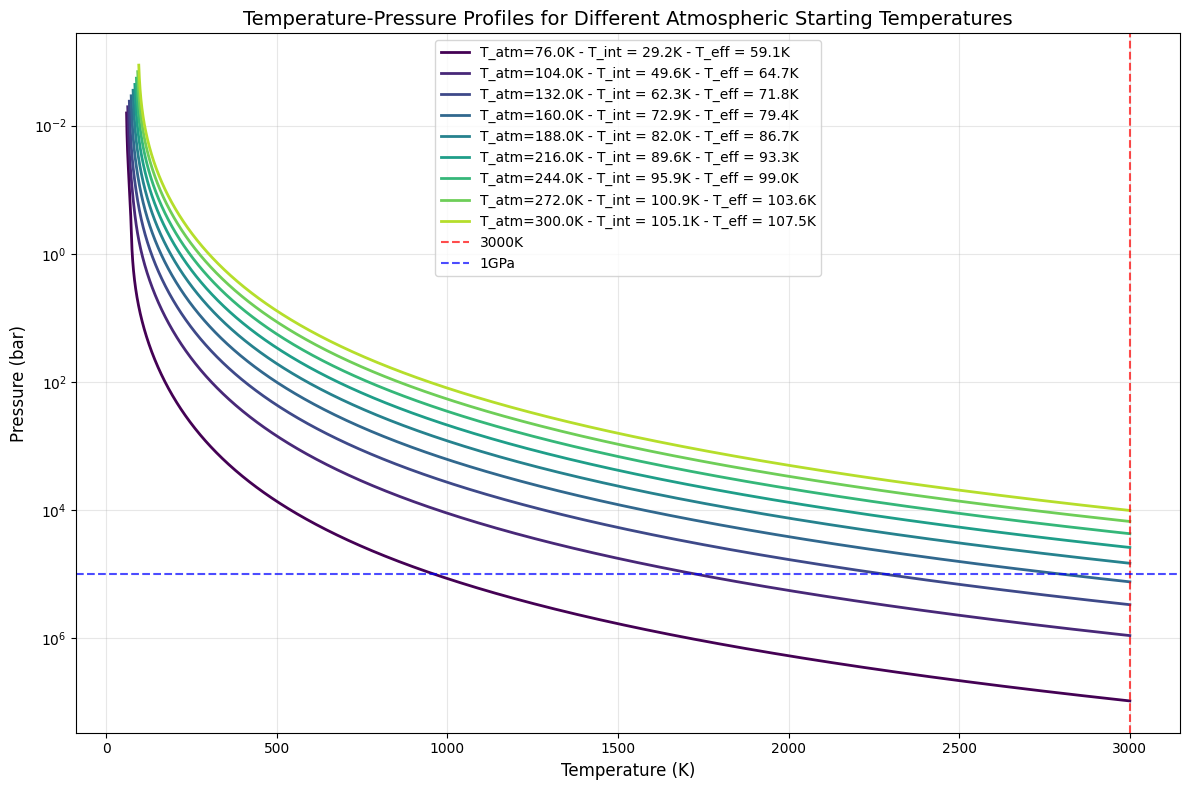

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Your 9 atmospheric starting temperatures (example values - adjust to yours)
T_atm = np.linspace(76,300,9)  # K

# Create the plot
plt.figure(figsize=(12, 8))

# For each starting temperature, plot the profile
for i in range(len(T_atm)):
    # Here you would call your model to get P-T profile
    # This is placeholder data - replace with your actual model results
    Tempi, Pressi, Tinti, Teffi  = Profile_From_1_bar(T_atm[i], 887, 1.5, 1000,3000)
    
    plt.semilogy(Tempi, Pressi, 
                 label=f'T_atm={T_atm[i]}K - T_int = {Tinti:.1f}K - T_eff = {Teffi:.1f}K',
                 linewidth=2,
                 color=plt.cm.viridis(i/len(T_atm)))

# Beautify the plot
plt.gca().invert_yaxis()  # Pressure decreases upward
plt.xlabel('Temperature (K)', fontsize=12)
plt.ylabel('Pressure (bar)', fontsize=12)
plt.title('Temperature-Pressure Profiles for Different Atmospheric Starting Temperatures', 
          fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Optional: Mark 3000K line
plt.axvline(x=3000, color='red', linestyle='--', alpha=0.7, label='3000K')
plt.axhline(y=10e4, color='blue', linestyle='--', alpha=0.7, label='1GPa')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
df = pd.read_csv('Opacities/table7.dat', 
                 sep='\s+',
                 comment='#',
                 skiprows=2,
                 header=None,
                 usecols=[0, 1, 3])  # Now this should work

df.columns = ['Temperature(K)', 'P(dyne/cm^2)', 'opacity_Rosseland_cm2_g']

print(df.head())

   Temperature(K)  P(dyne/cm^2)  opacity_Rosseland_cm2_g
0              75          10.0             1.165600e-07
1              75          30.0             3.488200e-07
2              75         100.0             1.160800e-06
3              75         300.0             3.479200e-06
4              75        1000.0             1.158900e-05


<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_909/1198640440.py:2: SyntaxWarning: invalid escape sequence '\s'
  sep='\s+',


In [15]:
# Check for Uranus at 76K, [M/H]=1.5
uranus = df[(df['P(dyne/cm^2)'] == 10**6) & (df['Temperature(K)'] == 76)]

if len(uranus) > 0:
    print(f"\nUranus at 76K: κ = {uranus['opacity_Rosseland_cm2_g'].values[0]:.6f} cm²/g")
else:
    # Find closest temperature to 76K for [M/H]=1.5
    mh15 = df[df['P(dyne/cm^2)'] == 10**6].copy()
    mh15['T_diff'] = abs(mh15['Temperature(K)'] - 76)
    closest = mh15.sort_values('T_diff').iloc[0]
    print(f"\nClosest to 76K: T={closest['Temperature(K)']}K, κ={closest['opacity_Rosseland_cm2_g']:.6f}")


Closest to 76K: T=75.0K, κ=0.011539


In [16]:
import pandas as pd
import numpy as np
from scipy.interpolate import griddata

# Assuming your table has columns: pressure, temperature, opacity
# (Adjust column names to match your actual data)
df = pd.read_csv('Opacities/table8.dat')  # or however you load it

# Option 1: Find closest match in table
def find_closest_opacity(df, target_P, target_T, P_col='Pressure', T_col='Temperature', k_col='Roseland_local'):
    """
    Find opacity by closest pressure and temperature in table
    """
    # Calculate weighted distance (normalize to avoid scale issues)
    P_norm = (df[P_col] - target_P) / df[P_col].std()
    T_norm = (df[T_col] - target_T) / df[T_col].std()
    
    # Euclidean distance
    df['distance'] = np.sqrt(P_norm**2 + T_norm**2)
    
    # Find closest point
    closest = df.loc[df['distance'].idxmin()]
    
    return closest[k_col]

# Option 2: Interpolate (more accurate)
def interpolate_opacity(df, target_P, target_T, P_col='Pressure', T_col='Temperature', k_col='Roseland_local'):
    """
    2D interpolation of opacity at given P, T
    """
    # Create grid points
    points = df[[P_col, T_col]].values
    values = df[k_col].values
    
    # Interpolate at target point
    opacity = griddata(points, values, (target_P, target_T), method='linear')
    
    return opacity

# Option 3: Simple 2D interpolator class
from scipy.interpolate import LinearNDInterpolator

class OpacityInterpolator:
    def __init__(self, df, P_col='Pressure', T_col='Temperature', k_col='Roseland_local'):
        """
        Initialize with dataframe containing P, T, opacity
        """
        self.P = df[P_col].values
        self.T = df[T_col].values
        self.k = df[k_col].values
        
        # Create interpolator
        self.interpolator = LinearNDInterpolator(
            list(zip(self.P, self.T)), 
            self.k,
            fill_value=np.nan
        )
    
    def get_opacity(self, P, T):
        """
        Get opacity at given pressure and temperature
        """
        return float(self.interpolator(P, T))

# Example usage
# Load your table (adjust file path and column names)
df = pd.read_csv('Opacities/table8.dat', sep=r'\s+', comment='#', skiprows=2, header=None)
df.columns = ['Temperature', 'Pressure', 'density', 'Roseland_local', 'Planck_local', 'Roseland_3000', 'Planck_3000', 'Roseland_4000', 'Planck_4000', 'Roseland_5000', 'Planck_5000', 'Roseland_6000', 'Planck_6000','Roseland_7000', 'Planck_7000']  # adjust!

# Create interpolator
interp = OpacityInterpolator(df, P_col='Pressure', T_col='Temperature', k_col='Roseland_local')

# Get opacity at any P, T
P_bar = 300
P_in_dyn = P_bar * 10**6
kappa = interp.get_opacity(P=P_in_dyn, T=1000)
print(f"Opacity at P=300 bar, T=300K: {kappa:.6f} cm²/g")

Opacity at P=300 bar, T=300K: 3.453000 cm²/g


In [17]:
def create_phase_lookup(filename):
    """
    Create a simple phase lookup function
    """
    # Load data
    data = []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                vals = line.split()
                float(vals[0])  # Test if numeric
                data.append([float(x) for x in vals[:11]])
            except (ValueError, IndexError):
                continue
    
    data = np.array(data)
    
    # Phase names
    phase_names = {
        -1: "Ice Ih", -2: "Ice II", -3: "Ice III",
        -5: "Ice V", -6: "Ice VI", -7: "Ice VII",
        3: "Vapor", 4: "Liquid", 5: "Supercritical"
    }
    
    # Extract columns
    temps = data[:, 1]      # Temperature in K
    press = data[:, 0] / 1e9  # Pressure in GPa
    phases = data[:, 10]     # Phase ID
    
    def lookup(T, P):
        """Return phase name at T(K) and P(GPa)"""
        # Find closest point
        distances = (temps - T)**2 + (press - P)**2
        idx = np.argmin(distances)
        phase_id = int(phases[idx])
        return phase_names.get(phase_id, f"Phase {phase_id}")
    
    return lookup

filename = '/home/mathias/H2Oeq/AQUA/Tables/aqua_eos_pt_v1_0.dat'
get_phase = create_phase_lookup(filename)

In [18]:
def read_aqua_simple(filename):
    """
    Read AQUA data file, skipping header lines that start with text
    """
    data = []
    line_count = 0
    skipped_count = 0
    
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            line_count += 1
            
            # Skip empty lines
            if not line:
                continue
            
            # Try to convert to float - if it fails, skip the line
            try:
                # Split and try to convert first element to float
                vals = line.split()
                if vals:  # Check if line has content
                    float(vals[0])  # Test if first value is a number
                    # If successful, convert all values to float
                    data.append([float(x) for x in vals[:11]])
            except ValueError:
                # This line contains text - skip it
                skipped_count += 1
                continue
    
    print(f"Read {line_count} total lines")
    print(f"Skipped {skipped_count} header/comment lines")
    print(f"Loaded {len(data)} data points")
    
    if len(data) == 0:
        raise ValueError("No data points were loaded! Check file format.")
    
    # Convert to DataFrame
    df = pd.DataFrame(data, columns=[
        'press_Pa', 'temp_K', 'rho', 'ad_grad', 's', 'u', 
        'c', 'mmw', 'x_ion', 'x_d', 'phase_id'
    ])
    
    # Convert pressure to GPa for convenience
    df['press_GPa'] = df['press_Pa'] / 1e9
    
    # Ensure phase_id is integer
    df['phase_id'] = df['phase_id'].astype(int)
    
    # Phase names mapping
    phase_names = {
        -1: "Ice Ih",
        -2: "Ice II",
        -3: "Ice III",
        -5: "Ice V",
        -6: "Ice VI",
        -7: "Ice VII",
        -10: "Ice X",
        3: "Vapor",
        4: "Liquid",
        5: "Supercritical/Superionic"
    }
    
    def get_phase(T, P):
        """Get phase at temperature T(K) and pressure P(GPa)"""
        # Find closest point
        distances = np.sqrt(
            (df['temp_K'] - T)**2 + 
            (df['press_GPa'] - P)**2
        )
        idx = distances.idxmin()
        pid = df.loc[idx, 'phase_id']
        
        # Also return density and actual T,P for verification
        actual_T = df.loc[idx, 'temp_K']
        actual_P = df.loc[idx, 'press_GPa']
        density = df.loc[idx, 'rho']
        
        phase_name = phase_names.get(pid, f"Unknown Phase ({pid})")
        
        return {
            'phase': phase_name,
            'phase_id': pid,
            'density': density,
            'actual_T': actual_T,
            'actual_P': actual_P,
            'distance': distances[idx]
        }
    
    # Print summary
    print(f"\n✅ Successfully loaded {len(df):,} data points")
    print(f"   Temperature range: {df['temp_K'].min():.0f} - {df['temp_K'].max():.0f} K")
    print(f"   Pressure range: {df['press_GPa'].min():.6f} - {df['press_GPa'].max():.2f} GPa")
    print(f"   Phase IDs present: {sorted(df['phase_id'].unique())}")
    
    return df, get_phase

# Alternative: Using pandas with comment handling
def read_aqua_pandas(filename):
    """
    Alternative method using pandas with comment handling
    """
    # Try to find where the numeric data starts
    with open(filename, 'r') as f:
        for i, line in enumerate(f):
            try:
                # Try to parse first few numbers
                vals = line.strip().split()
                if vals:
                    float(vals[0])
                    float(vals[1])
                    # If successful, this is the start of data
                    skip_rows = i
                    print(f"Data starts at line {i+1}")
                    break
            except (ValueError, IndexError):
                continue
    
    # Read with pandas, skipping header rows
    df = pd.read_csv(
        filename,
        sep=r'\s+',
        skiprows=skip_rows,
        names=['press_Pa', 'temp_K', 'rho', 'ad_grad', 's', 'u', 
               'c', 'mmw', 'x_ion', 'x_d', 'phase_id'],
        engine='python'
    )
    
    df['press_GPa'] = df['press_Pa'] / 1e9
    df['phase_id'] = df['phase_id'].astype(int)
    
    return df

# ===== USAGE =====

filename = '/home/mathias/H2Oeq/AQUA/Tables/aqua_eos_pt_v1_0.dat'

# Method 1: Simple function
print("="*60)
print("LOADING AQUA DATA")
print("="*60)
df, get_phase = read_aqua_simple(filename)

# Test points
print("\n" + "="*60)
print("TEST POINTS")
print("="*60)

test_points = [
    (300, 0.0001),   # Near surface
    (500, 1),         # 1 GPa
    (1000, 10),       # 10 GPa
    (2000, 50),       # 50 GPa
    (4000, 100),      # 100 GPa
]

for T, P in test_points:
    result = get_phase(T, P)
    print(f"T={T:4.0f}K, P={P:6.2f}GPa → {result['phase']:20s} "
          f"(ρ={result['density']:8.1f} kg/m³) "
          f"[closest point: T={result['actual_T']:.0f}K, P={result['actual_P']:.3f}GPa]")

# Quick lookup function for single use
def quick_phase(T, P):
    """Quick one-line phase lookup"""
    return get_phase(T, P)['phase']


LOADING AQUA DATA
Read 329012 total lines
Skipped 19 header/comment lines
Loaded 328993 data points

✅ Successfully loaded 328,993 data points
   Temperature range: 100 - 100000 K
   Pressure range: 0.000000 - 400000.00 GPa
   Phase IDs present: [np.int64(-10), np.int64(-7), np.int64(-6), np.int64(-5), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(3), np.int64(4), np.int64(5)]

TEST POINTS
T= 300K, P=  0.00GPa → Liquid               (ρ=   996.0 kg/m³) [closest point: T=302K, P=0.000GPa]
T= 500K, P=  1.00GPa → Liquid               (ρ=  1139.4 kg/m³) [closest point: T=501K, P=1.003GPa]
T=1000K, P= 10.00GPa → Supercritical/Superionic (ρ=  1618.3 kg/m³) [closest point: T=1000K, P=10.034GPa]
T=2000K, P= 50.00GPa → Supercritical/Superionic (ρ=  2338.4 kg/m³) [closest point: T=1995K, P=50.297GPa]
T=4000K, P=100.00GPa → Supercritical/Superionic (ρ=  2724.1 kg/m³) [closest point: T=3981K, P=100.366GPa]


In [19]:
def list_phases(Temperatures, Pressures):
    #pressures in Gpa, Temperatures in kelvin
    phases = []
    for i in range(len(Temperatures)):
        phase = quick_phase(Temperatures[i], Pressures[i])
        phases.append(phase)
        phases = list(set(phases))
    return phases

In [20]:
T_solar = 5772
R_solar = 6.957e8
d_solar_Uranus = 2876679082000

T_irr = T_solar * np.sqrt(R_solar/d_solar_Uranus)

T_eff_end = 59.1 #pm 0.3 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_int_end = (T_eff_end**(4) - T_eq**(4))**(1/4)

In [21]:
T_end = 76 
T_eff = np.linspace(300, 59.1,100)
T_int = (T_eff**(4) - T_eq**(4))**(1/4)
P_end = 1 #in bar
#we can find scale and relation now

In [22]:
def opacity_with_methane(T, kappa0=3e-4, T0=76, beta=-0.75):
    # Baseline CIA opacity
    kappa_cia = kappa0 * (T / T0) ** beta
    
    # Methane condensation effect (turns on below ~70K)
    T_condense = 70
    if T < T_condense:
        # Extra opacity from methane clouds/haze
        methane_factor = 1.0 + 0.5 * (1 - T/T_condense)**2
    else:
        methane_factor = 1.0

In [23]:
Pressure = 3447 * 10**6 
Temp = np.linspace(10,5000, 1000)
met = 1
opacities = []
for temp in Temp:
    opacities.append(opacity(Pressure, temp, met))
    

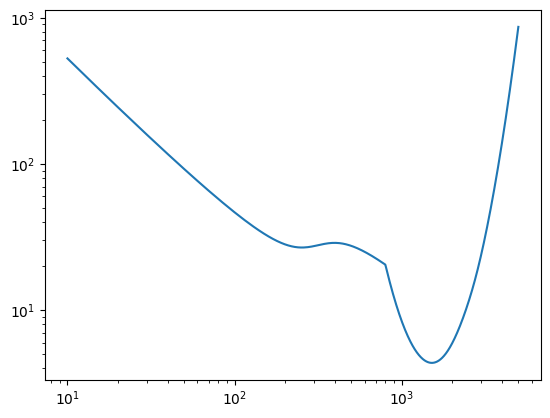

In [24]:
plt.plot(Temp, opacities)  # x and y are your lists/arrays
plt.xscale('log')
plt.yscale('log')
plt.show()

In [25]:
g_76 = 887
Press = 10**6 #to dyne/cm^2
optical_depth = Press*opacity(Press, 76, 0)/g_76
print(optical_depth)

11.80561585825792


In [26]:
tau = np.logspace(-1,2,1000)
print(tau)
final_scale = find_scale(76,T_int_end,0.4, 1, tau, 1)
print(final_scale)

[  0.1                 0.100693863147603   0.101392540755882
   0.102096066230605   0.102804473209331   0.103517795563018
   0.10423606739764    0.104959323055823   0.10568759711848
   0.106420924406472   0.107159339982267   0.107902879151618
   0.108651577465254   0.109405470720574   0.110164594963366
   0.110928986489522   0.111698681846782   0.112473717836475
   0.113254131515281   0.114039960197003   0.114831241454351
   0.115628013120738   0.116430313292088   0.11723818032866
   0.118051652856881   0.11887076977119    0.119695570235904
   0.120526093687084   0.121362379834424   0.122204468663149
   0.123052400435926   0.123906215694792   0.124765955263087
   0.125631660247412   0.12650337203959    0.127381132318648
   0.128264983052806   0.129154966501488   0.130051125217341
   0.130953502048267   0.131862140139475   0.132777082935543
   0.133698374182495   0.134626057929891   0.135560178532937
   0.136500780654601   0.137447909267754   0.138401609657313
   0.139361927422414   0.1

In [27]:
woop = find_tau(tau,29,0.3, 76, 2.11)
print(woop)

5.311630696018665


In [28]:
#So find gamma as to make it align with the 1 bar level 
gamma = np.logspace(-2,0,1000)
final_gamma = find_gamma(optical_depth,29, gamma, 76, 0.1)
print(final_gamma)
find_tau(tau,29,final_gamma, 76, 2.11)

0.377047291717951


np.float64(11.805615858257768)

In [29]:
#Step 1 Take 1 bar 76 K and surface gravity
#Step 2 deduce thermal opacity from here
#Step 3 compare with Guillot and find gamma 
#Step 4 Use different effective temperatures to construct different temperature profiles in time 
#Step 5 find corresponding temperatures at certain pressures
#Step 6 compare with solidus, liquidus, when no magma ocean?

In [30]:
# Open the file and skip lines until we find numeric data
data = []
with open("/home/mathias/perplextext/uranus_magma/uranus_1.tab") as textwriter:
    for line in textwriter:
        line = line.strip()
        # Skip empty lines and comments
        if line == "" or line.startswith("#"):
            continue
        # Split the line by whitespace and convert to float
        try:
            numbers = [float(x) for x in line.split()]
            data.append(numbers)
        except ValueError:
            # Skip lines that cannot be converted (headers, etc.)
            continue


In [31]:

df = pd.DataFrame(data, columns=["P_bar", "T_K", "melt_vo"])

# Convert pressure to GPa


# Example: find solidus and liquidus (ignoring NaNs)
solidus = df.groupby("P_bar").apply(lambda g: g.loc[g['melt_vo']>0, 'T_K'].min())
liquidus = df.groupby("P_bar").apply(lambda g: g.loc[g['melt_vo']>0, 'T_K'].max())

print("Solidus (K) vs P (bar):\n", solidus)
print("Liquidus (K) vs P (bar):\n", liquidus)

Solidus (K) vs P (bar):
 P_bar
2.000000              NaN
3.000000              NaN
24.038462             NaN
313.000000            NaN
500.000000            NaN
                   ...   
987192.000000     884.615
990394.000000     884.615
993596.000000     884.615
996798.000000     884.615
1000000.000000    884.615
Length: 319, dtype: float64
Liquidus (K) vs P (bar):
 P_bar
2.000000              NaN
3.000000              NaN
24.038462             NaN
313.000000            NaN
500.000000            NaN
                   ...   
987192.000000     6942.31
990394.000000     6942.31
993596.000000     6942.31
996798.000000     6942.31
1000000.000000    6942.31
Length: 319, dtype: float64


/tmp/ipykernel_909/1260583982.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  solidus = df.groupby("P_bar").apply(lambda g: g.loc[g['melt_vo']>0, 'T_K'].min())
/tmp/ipykernel_909/1260583982.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  liquidus = df.groupby("P_bar").apply(lambda g: g.loc[g['melt_vo']>0, 'T_K'].max())


In [32]:
rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
fO2_log10_shift = -5.0
shift = f"{fO2_log10_shift:.2g}"
filename = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"
Pressures_file = pd.read_excel(filename, sheet_name="state")["pressure"]
Temperatures_file = pd.read_excel(filename, sheet_name="state")["temperature"]

/tmp/ipykernel_909/2092539684.py:53: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  x_solution = fsolve(ze, initial_guess)
/tmp/ipykernel_909/2092539684.py:18: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  x_solution = fsolve(g, initial_guess)


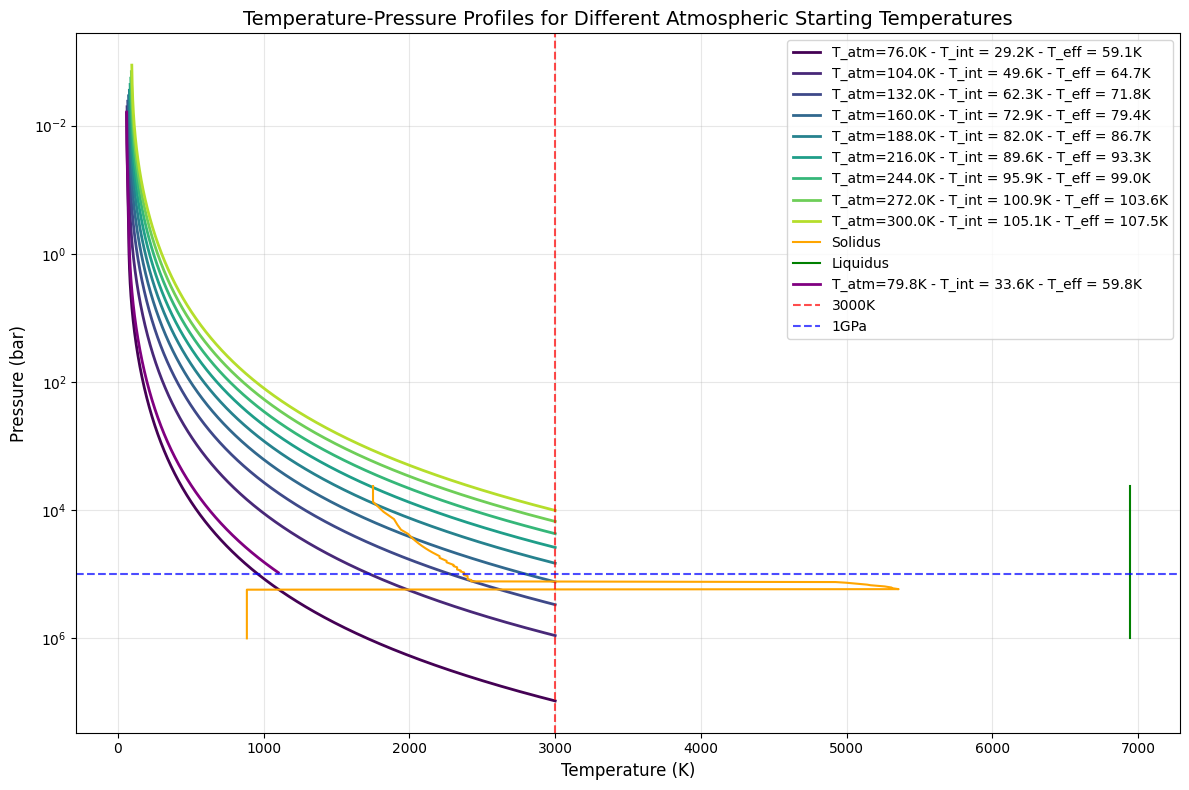

In [33]:
import numpy as np
import matplotlib.pyplot as plt
Tempi_sim,Pressi_sim, Tinti_sim, Teffi_sim, Tatmo_sim =   Pressure_and_Temperature_to_profile(Pressures_file[49], 1100, 1.5, 887,1000)
# Your 9 atmospheric starting temperatures (example values - adjust to yours)
T_atm = np.linspace(76,300,9)  # K

# Create the plot
plt.figure(figsize=(12, 8))

# For each starting temperature, plot the profile
for i in range(len(T_atm)):
    # Here you would call your model to get P-T profile
    # This is placeholder data - replace with your actual model results
    Tempi, Pressi, Tinti, Teffi  = Profile_From_1_bar(T_atm[i], 887, 1.5, 1000,3000)
    
    plt.semilogy(Tempi, Pressi, 
                 label=f'T_atm={T_atm[i]:.1f}K - T_int = {Tinti:.1f}K - T_eff = {Teffi:.1f}K',
                 linewidth=2,
                 color=plt.cm.viridis(i/len(T_atm)))

plt.plot(solidus.values, solidus.index, color='orange', label='Solidus')
# Plot liquidus
plt.plot(liquidus.values, liquidus.index, color='green', label='Liquidus')

plt.semilogy(Tempi_sim, Pressi_sim, 
                label=f'T_atm={Tatmo_sim[0]:.1f}K - T_int = {Tinti_sim:.1f}K - T_eff = {Teffi_sim:.1f}K',
                linewidth=2,
                color='purple')
# Beautify the plot
plt.gca().invert_yaxis()  # Pressure decreases upward
plt.xlabel('Temperature (K)', fontsize=12)
plt.ylabel('Pressure (bar)', fontsize=12)
plt.title('Temperature-Pressure Profiles for Different Atmospheric Starting Temperatures', 
          fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Optional: Mark 3000K line
plt.axvline(x=3000, color='red', linestyle='--', alpha=0.7, label='3000K')
plt.axhline(y=10e4, color='blue', linestyle='--', alpha=0.7, label='1GPa')
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
import numpy as np

def peridotite_solidus(P_bar): #On the cooling of a deep terrestrial magma ocean
    """
    P_bar: pressure in bar
    Returns: solidus temperature in K
    """
    P_Pa = P_bar*10**5
    T_sol = 1661.2*((P_Pa/(1.336*10**9))+1)**(1/7.437)
    return T_sol

def peridotite_liquidus(P_bar):
    """
    P_bar: pressure in bar
    Returns: liquidus temperature in K
    """
    P_Pa = P_bar*10**5
    T_liq = 1982.1*((P_Pa/(6.594*10**9))+1)**(1/5.374)
    
    return T_liq

# Test at key pressures
pressures = [100, 1000, 10000, 100000, 1000000, 10000000,100000000,1000000000]  # bar
print("Pressure (bar) | Solidus (K) | Liquidus (K)")
print("-" * 45)
for P in pressures:
    Ts = peridotite_solidus(P)
    Tl = peridotite_liquidus(P)
    print(f"{P:12,d} | {Ts:10.0f} | {Tl:10.0f}")

Pressure (bar) | Solidus (K) | Liquidus (K)
---------------------------------------------
         100 |       1663 |       1983
       1,000 |       1677 |       1988
      10,000 |       1791 |       2035
     100,000 |       2215 |       2353
   1,000,000 |       2973 |       3327
  10,000,000 |       4045 |       5052
 100,000,000 |       5513 |       7746
1,000,000,000 |       7513 |      11888


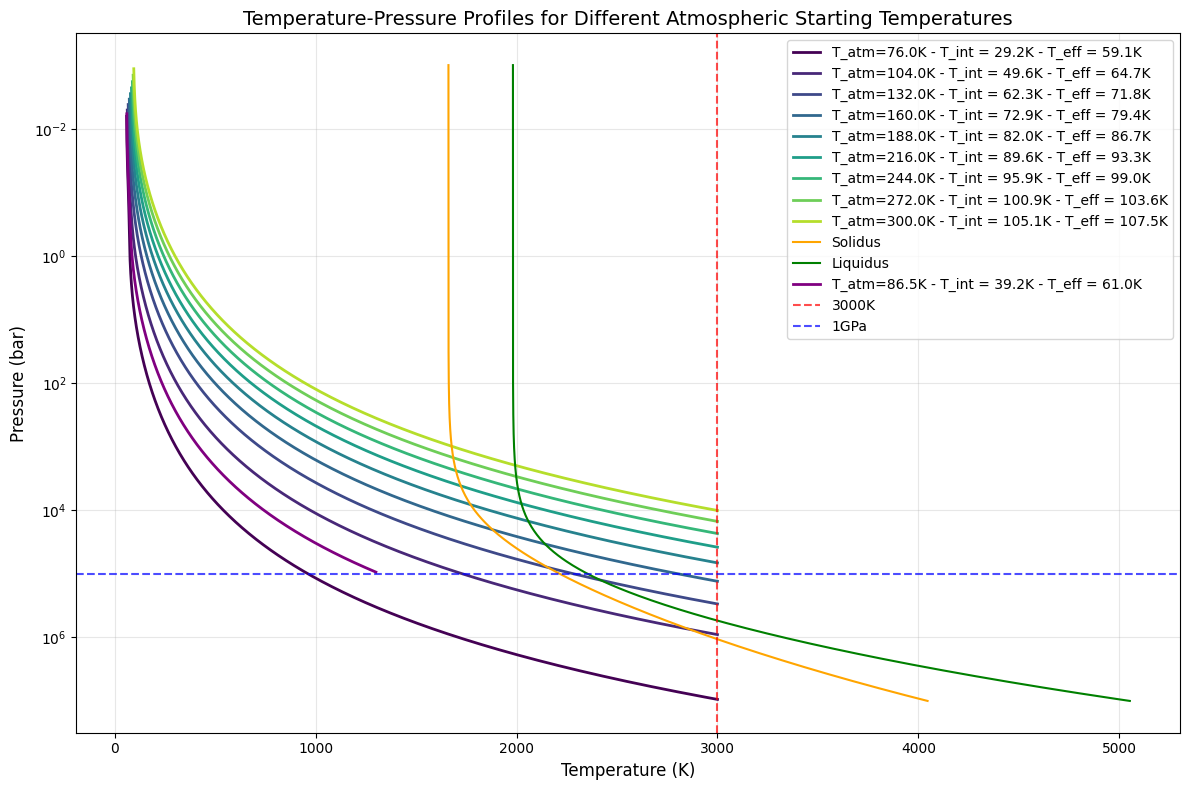

In [50]:
import numpy as np
import matplotlib.pyplot as plt
Tempi_sim,Pressi_sim, Tinti_sim, Teffi_sim, Tatmo_sim =   Pressure_and_Temperature_to_profile(Pressures_file[49], 1300, 1.5, 887,1000)
# Your 9 atmospheric starting temperatures (example values - adjust to yours)
T_atm = np.linspace(76,300,9)  # K
Pressures_liq_sol = np.logspace(-3,7,1000)
# Create the plot
plt.figure(figsize=(12, 8))

# For each starting temperature, plot the profile
for i in range(len(T_atm)):
    # Here you would call your model to get P-T profile
    # This is placeholder data - replace with your actual model results
    Tempi, Pressi, Tinti, Teffi  = Profile_From_1_bar(T_atm[i], 887, 1.5, 1000,3000)
    
    plt.semilogy(Tempi, Pressi, 
                 label=f'T_atm={T_atm[i]:.1f}K - T_int = {Tinti:.1f}K - T_eff = {Teffi:.1f}K',
                 linewidth=2,
                 color=plt.cm.viridis(i/len(T_atm)))

plt.plot(peridotite_solidus(Pressures_liq_sol), Pressures_liq_sol, color='orange', label='Solidus')
# Plot liquidus
plt.plot(peridotite_liquidus(Pressures_liq_sol), Pressures_liq_sol, color='green', label='Liquidus')

plt.semilogy(Tempi_sim, Pressi_sim, 
                label=f'T_atm={Tatmo_sim:.1f}K - T_int = {Tinti_sim:.1f}K - T_eff = {Teffi_sim:.1f}K',
                linewidth=2,
                color='purple')
# Beautify the plot
plt.gca().invert_yaxis()  # Pressure decreases upward
plt.xlabel('Temperature (K)', fontsize=12)
plt.ylabel('Pressure (bar)', fontsize=12)
plt.title('Temperature-Pressure Profiles for Different Atmospheric Starting Temperatures', 
          fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Optional: Mark 3000K line
plt.axvline(x=3000, color='red', linestyle='--', alpha=0.7, label='3000K')
plt.axhline(y=10e4, color='blue', linestyle='--', alpha=0.7, label='1GPa')
plt.legend()

plt.tight_layout()
plt.show()